In [4]:
import numpy as np 
from pydrake.systems.controllers import LinearQuadraticRegulator
import matplotlib.pyplot as plt

In [7]:
from dataclasses import dataclass

@dataclass
class Config:
    g: float = 9.81
    l: float = 1. 
    m: float = 1.
    b: float = 1.0

config = Config()

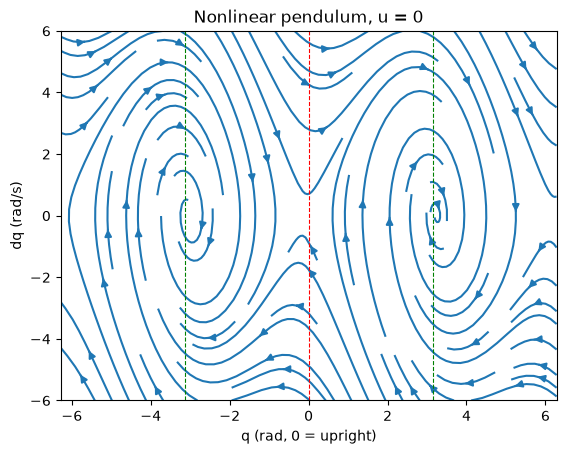

In [ ]:
q, dq = np.meshgrid(np.linspace(-2*np.pi, 2*np.pi, 101),
                    np.linspace(-6, 6, 101))


u = 1.0 
beta = config.b / (config.m * (config.l**2))
dx = (dq, ((config.g / config.l) * np.sin(q)) - ( beta * dq) + (u / (config.m * (config.l ** 2))))

plt.streamplot(q, dq, *dx)
plt.axvline(0, color="r", lw=0.8, ls="--")          # upright
for k in (-1, 1):
    plt.axvline(k*np.pi, color="g", lw=0.8, ls="--")  # hanging
plt.xlabel("q (rad, 0 = upright)")
plt.ylabel("dq (rad/s)")
plt.title("Nonlinear pendulum, u = 0")
plt.show()

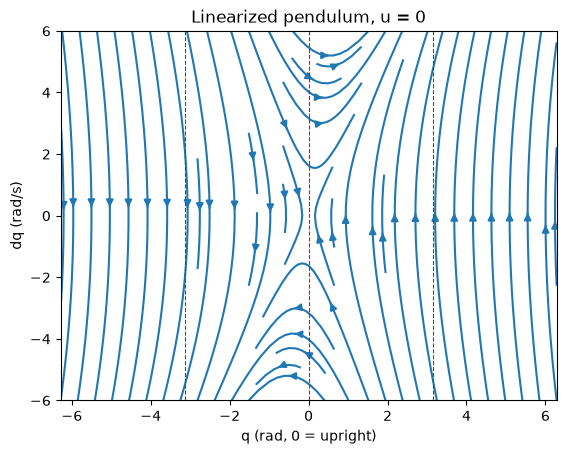

In [ ]:
q, dq = np.meshgrid(np.linspace(-2*np.pi, 2*np.pi, 101), np.linspace(-6, 6, 101))


u = 0.0 

A = np.array([[0., 1.], 
              [config.g / config.l, -beta]])
B = np.array([[0.0],
              [1.0 / (config.m * config.l ** 2)]])

dq_ = A[0, 0] * q + A[0, 1] * dq + B[0,0] * u
ddq_ =  A[1, 0] * q + A[1, 1] * dq + B[1,0] * u 
plt.streamplot(q, dq, dq_, ddq_)
plt.axvline(0, color="r", lw=0.8, ls="--")          # upright
for k in (-1, 1):
    plt.axvline(k*np.pi, color="g", lw=0.8, ls="--")  # hanging
plt.xlabel("q (rad, 0 = upright)")
plt.ylabel("dq (rad/s)")
plt.title("Linearized pendulum, u = 0")
plt.show()

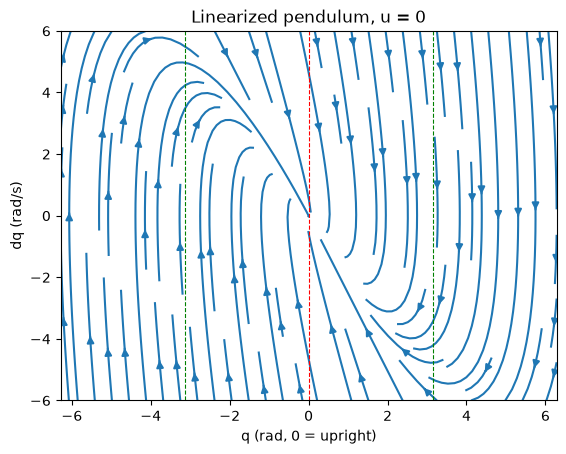

In [30]:
Q = np.eye(2)
R = np.array([[1.0]])

K, S = LinearQuadraticRegulator(A, B, Q, R)

u = -(K[0, 0]*q + K[0, 1]*dq) 

dq_ = A[0, 0] * q + A[0, 1] * dq + B[0,0] * u
ddq_ =  A[1, 0] * q + A[1, 1] * dq + B[1,0] * u 
plt.streamplot(q, dq, dq_, ddq_)
plt.axvline(0, color="r", lw=0.8, ls="--")          # upright
for k in (-1, 1):
    plt.axvline(k*np.pi, color="g", lw=0.8, ls="--")  # hanging
plt.xlabel("q (rad, 0 = upright)")
plt.ylabel("dq (rad/s)")
plt.title("Linearized pendulum, u = 0")
plt.show()

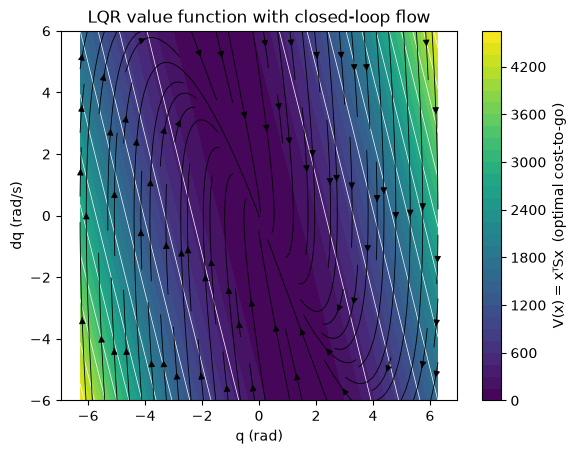

In [42]:
V = S[0, 0]*q**2 + 2*S[0, 1]*q*dq + S[1, 1]*dq**2

plt.contourf(q, dq, V, levels=30, cmap="viridis")
plt.colorbar(label="V(x) = xᵀSx  (optimal cost-to-go)")
plt.contour(q, dq, V, levels=12, colors="white", linewidths=0.5)
plt.streamplot(q, dq, dq_, ddq_, color="k", density=1.0, linewidth=0.6)
plt.xlabel("q (rad)"); plt.ylabel("dq (rad/s)")
plt.title("LQR value function with closed-loop flow")
plt.show()

In [43]:
from pydrake.examples import AcrobotPlant 

In [ ]:
plant = AcrobotPlant()

context = plant.CreateDefaultContext()

x_nom = np.array([np.pi, 0., 0., 0.])
context.SetContinuousState(x_nom)
plant.get_input_port(0).FixValue(context, [0.0])